# Assignment 2 — GraphSAGE with a configurable observation gap

**Run from your repository root**, beside `data/`, `scripts/`, and `submission/`.
The defaults use September 1–November 13, 2026 **UTC**, with an exclusive observation
end of November 14 at 00:00 UTC. Confirm these boundaries against your actual downloads.
This is the newly preprocessed eight-table dataset, not the previous supplied release.

This notebook builds a **heterogeneous mean-GraphSAGE** model over all eight table types
and their foreign keys, with reverse relationships. It is implemented directly in PyTorch:
relation-specific neighbor means plus a transformed root representation. This avoids PyG
and native sampling-extension installation. It is snapshot-based temporal modeling, not
a recurrent or continuous-time GNN.

Included: partial-column loading, chronological splits with an observation-gap embargo,
six-label targets, recency and 7/14/28-day counts, three controlled model variants,
a past-week reference, validation-only threshold/epoch selection, holdout CSVs and charts,
final historical refitting, and exact official CSV validation. No download is required.
No future target labels are requested for the official forecast.

**First run:** edit Section 2 paths if needed, then run in order. Keep `RUN_FINAL=False`
until training is complete and you have the latest official test list and your student ID.
The forecast is November 22–29 Taiwan time, not the older November 12 forecast.

**Execution status:** the authoring environment lacks PyTorch and a Parquet engine.
Pure-Python/NumPy/pandas preprocessing, boundary cases, split logic, and evaluator behavior
are tested separately. Neural forward/backward and real-data training must run on your
computer; no accuracy or runtime is claimed. A small neural self-check runs before training.


## 1. Packages


In [ ]:
# Uncomment only if these packages are missing from this kernel.
# %pip install numpy pandas pyarrow matplotlib torch


In [2]:
from pathlib import Path
from functools import lru_cache
import copy, gc, hashlib, importlib.util, json, platform, random, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch
from torch import nn
import torch.nn.functional as F


KeyboardInterrupt: 

## 2. Configuration — the main settings to edit
All internal timestamps are timezone-naive **UTC**. `OBSERVATION_END` is exclusive and
is a declared collection boundary, not the maximum observed event timestamp. Missing GH
Archive hours are not converted into extra negative evidence. If you know the dataset has
missing hours, add their dates to `EXCLUDED_DATES_UTC`; affected feature and target windows
are excluded from historical examples. Inspect the coverage audit before trusting scores.

The current gap is derived as forecast start minus observation end: **7 days 16 hours**.
The same gap is applied to historical examples. Updating the data later requires replacing
all eight tables consistently, editing the declared boundaries/exclusions, and rerunning
from the top. The gap then changes automatically. Do not change only the forecast date.

Graph activity nodes are restricted to a recent window, then older visible parent records
are added to close FK references. Users/repositories visible at the cutoff are retained.
We do not persist large graph snapshots. Sparse matrix aggregation avoids an E×hidden-size
message tensor. Reduce hidden size/history if memory is still insufficient.


In [ ]:
DATA_DIR = Path("data/db")
TEST_INPUT = Path("submission/test_input.csv")
EVALUATOR = Path("scripts/evaluate.py")
OUT = Path("generated_graphsage")
OUT.mkdir(parents=True, exist_ok=True)

DATA_START = pd.Timestamp("2026-03-01 00:00:00")
OBSERVATION_END = pd.Timestamp("2026-11-14 00:00:00")
TARGET_START = pd.Timestamp("2026-11-22 00:00:00", tz="Asia/Taipei").tz_convert("UTC").tz_localize(None)
HORIZON = pd.Timedelta(days=7)
GAP = max(pd.Timedelta(0), TARGET_START - OBSERVATION_END)
EXCLUDED_DATES_UTC = []   # e.g. ["2026-10-05"] if that UTC day has known gaps

GRAPH_LOOKBACK_DAYS = 28
COUNT_WINDOWS = (7, 14, 28)
MIN_HISTORY_DAYS = 14     # 28-day counts can have partial coverage; encoded explicitly
TRAIN_STRIDE_DAYS = 3    # overlapping train labels are allowed; splits are purged
MAX_TRAIN_SNAPSHOTS = 100
VALIDATION_WEEKS = 1
CACHE_SNAPSHOTS = 1      # CPU graph cache; increase only if RAM permits
HIDDEN = 32
EPOCHS = 15
PATIENCE = 4
LEARNING_RATE = 0.003
WEIGHT_DECAY = 0.0005
DROPOUT = 0.10
SEED = 42
DEVICE = torch.device("cpu")  # change to torch.device("cuda") only if available
RUN_ABLATIONS = False
RUN_FINAL = True
STUDENT_ID = "115701801"
HASH_INPUT_FILES = False  # optional full input SHA256 scan; adds disk reads

ACTIVITIES = ["open_pr", "open_issue", "issue_comment", "pr_review", "pr_review_comment", "push"]
OUTPUT_COLUMNS = ["UserID"] + ACTIVITIES
assert DATA_START < OBSERVATION_END <= TARGET_START
assert TRAIN_STRIDE_DAYS > 0 and VALIDATION_WEEKS > 0 and MIN_HISTORY_DAYS >= 7
assert all(d <= GRAPH_LOOKBACK_DAYS for d in COUNT_WINDOWS)
if DEVICE.type == "cuda" and not torch.cuda.is_available():
    raise RuntimeError("CUDA unavailable. Leave DEVICE set to CPU.")
torch.set_num_threads(min(4, torch.get_num_threads()))
torch.use_deterministic_algorithms(True)
print("Feature/forecast gap:", GAP, "| Device:", DEVICE)
print("Official target UTC:", TARGET_START, "to", TARGET_START + HORIZON)


Feature/forecast gap: 7 days 16:00:00 | Device: cpu
Official target UTC: 2026-11-21 16:00:00 to 2026-11-28 16:00:00


## 3. Schema and lean loading
PK/FK values are row indices **within the same preprocessing run**. They are not numerical
features. Only required ID/time columns are read. Mutable text, usernames, closure state,
merge outcomes, and review dismissal information are excluded from feature vectors.
`merged_by_id` is kept only as a graph relation once `merged_at` is strictly before cutoff.
The schema has 20 forward FK relations; the graph additionally includes their reverses.


In [4]:
PK = {"Users": "user_id", "Repositories": "repo_id", "PullRequests": "pr_id",
      "Issues": "issue_id", "IssueComments": "comment_id", "PRReviews": "review_id",
      "PRReviewComments": "comment_id", "Pushes": "push_id"}
ROW_TIME = {name: ("created_at" if name in ["IssueComments", "PRReviewComments", "Pushes"]
                   else "first_seen_at") for name in PK}
FKS = {
    "Users": {}, "Repositories": {},
    "PullRequests": {"repo_id": "Repositories", "author_id": "Users", "merged_by_id": "Users"},
    "Issues": {"repo_id": "Repositories", "author_id": "Users", "pull_request_id": "PullRequests", "assignee_id": "Users"},
    "IssueComments": {"issue_id": "Issues", "repo_id": "Repositories", "author_id": "Users"},
    "PRReviews": {"pr_id": "PullRequests", "repo_id": "Repositories", "reviewer_id": "Users"},
    "PRReviewComments": {"pr_id": "PullRequests", "repo_id": "Repositories", "author_id": "Users",
                         "pull_request_review_id": "PRReviews", "in_reply_to_id": "PRReviewComments"},
    "Pushes": {"user_id": "Users", "repo_id": "Repositories"},
}
SPECS = [
    ("open_pr", "PullRequests", "author_id", "created_at"),
    ("open_issue", "Issues", "author_id", "created_at"),
    ("issue_comment", "IssueComments", "author_id", "created_at"),
    ("pr_review", "PRReviews", "reviewer_id", "submitted_at"),
    ("pr_review_comment", "PRReviewComments", "author_id", "created_at"),
    ("push", "Pushes", "user_id", "created_at"),
]
RELATIONS = []
for source, fks in FKS.items():
    for column, dest in fks.items():
        RELATIONS += [(source, column, dest), (dest, "rev_" + source + "_" + column, source)]
assert len(RELATIONS) == 40

def needed_columns(name):
    cols = {PK[name], ROW_TIME[name], *FKS[name]}
    if name == "Users": cols.update(["github_user_id", "is_cohort"])
    if name == "Issues": cols.add("is_pull_request")
    if name == "PullRequests": cols.add("merged_at")
    for _, table, _, time in SPECS:
        if table == name: cols.add(time)
    return sorted(cols)

def load_tables(directory):
    result, audit = {}, []
    for name in PK:
        path = directory / f"{name}.parquet"
        if not path.is_file(): raise FileNotFoundError(path.resolve())
        df = pd.read_parquet(path, columns=needed_columns(name))
        for column in df.columns:
            if column.endswith("_at"):
                df[column] = pd.to_datetime(df[column], utc=True).dt.tz_localize(None)
        assert df[PK[name]].notna().all() and df[PK[name]].is_unique, name
        assert df[ROW_TIME[name]].notna().all(), name
        # Keep PK/FK integrity. Some parent/comment creation times predate collection.
        # Snapshot visibility and label-as-of filters enforce the declared upper bound.
        result[name] = df
        audit.append({"table": name, "rows": len(df), "first_row": df[ROW_TIME[name]].min(),
                      "last_row": df[ROW_TIME[name]].max(),
                      "RAM_MB": df.memory_usage(deep=True).sum() / 1e6})
    users = result["Users"]
    assert users.github_user_id.is_unique and users.github_user_id.notna().all()
    for source, fks in FKS.items():
        for col, dest in fks.items():
            refs = result[source][col].dropna()
            if not refs.isin(result[dest][PK[dest]]).all():
                raise ValueError(f"Broken FK {source}.{col}. Use one consistent release and check DATA_START/OBSERVATION_END.")
    return result, pd.DataFrame(audit)


In [5]:
TABLES, table_summary = load_tables(DATA_DIR)
display(table_summary)
table_summary.to_csv(OUT / "table_summary.csv", index=False)
print("Cohort users:", int(TABLES["Users"].is_cohort.sum()))
print("These row maxima do not establish continuous hourly archive coverage.")


,table,rows,first_row,last_row,RAM_MB
0,Users,29627,2026-03-01 00:00:22,2026-11-13 21:43:53,0.800061
1,Repositories,88955,2026-03-01 00:00:22,2026-11-13 23:15:40,1.423412
2,PullRequests,186211,2026-03-01 00:01:06,2026-11-13 23:54:49,10.986581
3,Issues,106024,2026-03-01 00:01:26,2026-11-13 23:46:08,6.573620
4,IssueComments,56616,2026-03-01 00:01:26,2026-11-13 23:41:00,2.434620
5,PRReviews,46500,2026-03-01 00:01:06,2026-11-13 23:50:49,2.371632
6,PRReviewComments,33549,2026-03-01 00:01:06,2026-11-13 23:44:05,2.046621
7,Pushes,1229073,2026-03-01 00:00:22,2026-11-13 22:07:46,41.788614


Cohort users: 9000
These row maxima do not establish continuous hourly archive coverage.


## 4. Two-clock event ledger and separate targets
Event occurrence determines labels. Row availability (also bounded by actor/repository
availability) determines historical feature access. A PR observed later is not an opening
at its observation time. Unknown opening/submission times are not invented. Issue comments
include PR conversations; opening-issue labels exclude PRs. Only cohort actors enter the
activity ledger; other visible users may still be relational context.

For labels, `as_of` is the boundary by which their records must be known. Training labels
must be known before validation's observation cutoff. No label is stored as a node feature.
Users with no events in the target window receive zero labels. Known missing dates cause
windows to be excluded; unknown upstream gaps remain a dataset limitation.


In [6]:
def make_ledger(tables):
    users = tables["Users"].set_index("user_id")
    repos = tables["Repositories"].set_index("repo_id")
    frames, audit = [], []
    for activity, table, actor, event_time in SPECS:
        source = tables[table]
        if activity == "open_issue": source = source.loc[~source.is_pull_request.fillna(False).astype(bool)]
        f = pd.DataFrame({"user_id": source[actor], "repo_id": source.repo_id,
                          "event_time": source[event_time], "known_at": source[ROW_TIME[table]]})
        missing = int(f[["user_id", "repo_id", "event_time", "known_at"]].isna().any(axis=1).sum())
        f = f.dropna().copy()
        f[["user_id", "repo_id"]] = f[["user_id", "repo_id"]].astype("int64")
        f = f.loc[f.user_id.map(users.is_cohort).fillna(False).astype(bool) & f.event_time.ge(DATA_START)].copy()
        f["known_at"] = pd.concat([f.known_at, f.event_time,
            f.user_id.map(users.first_seen_at), f.repo_id.map(repos.first_seen_at)], axis=1).max(axis=1)
        f["activity"] = activity
        frames.append(f)
        audit.append({"activity": activity, "usable": len(f), "missing_actor_repo_or_time": missing})
    return pd.concat(frames, ignore_index=True).sort_values("event_time").reset_index(drop=True), pd.DataFrame(audit)

MISSING_DAYS = [pd.Timestamp(d).normalize() for d in EXCLUDED_DATES_UTC]

def interval_has_gap(start, end):
    return any(d < end and d + pd.Timedelta(days=1) > start for d in MISSING_DAYS)

def eligible_users(t, tables= None):
    tables = TABLES if tables is None else tables
    cutoff = pd.Timestamp(t) - GAP
    u = tables["Users"]
    return u.loc[u.is_cohort.eq(True) & u.first_seen_at.lt(cutoff)].sort_values("user_id").reset_index(drop=True)

def make_targets(t, users, as_of, ledger=None):
    t, as_of = pd.Timestamp(t), pd.Timestamp(as_of)
    if t + HORIZON > as_of: raise ValueError("Target week not fully observed by as_of.")
    if interval_has_gap(t, t + HORIZON): raise ValueError("Target week includes a known missing day.")
    ledger = EVENTS if ledger is None else ledger
    f = ledger.loc[ledger.event_time.ge(t) & ledger.event_time.lt(t + HORIZON) & ledger.known_at.lt(as_of)]
    counts = f.groupby(["user_id", "activity"]).size().unstack("activity")
    y = counts.reindex(index=users.user_id, columns=ACTIVITIES).fillna(0).gt(0).to_numpy(dtype=np.float32)
    return y


,activity,usable,missing_actor_repo_or_time
0,open_pr,78212,106200
1,open_issue,55524,0
2,issue_comment,56616,0
3,pr_review,45872,0
4,pr_review_comment,33549,0
5,push,1229073,0


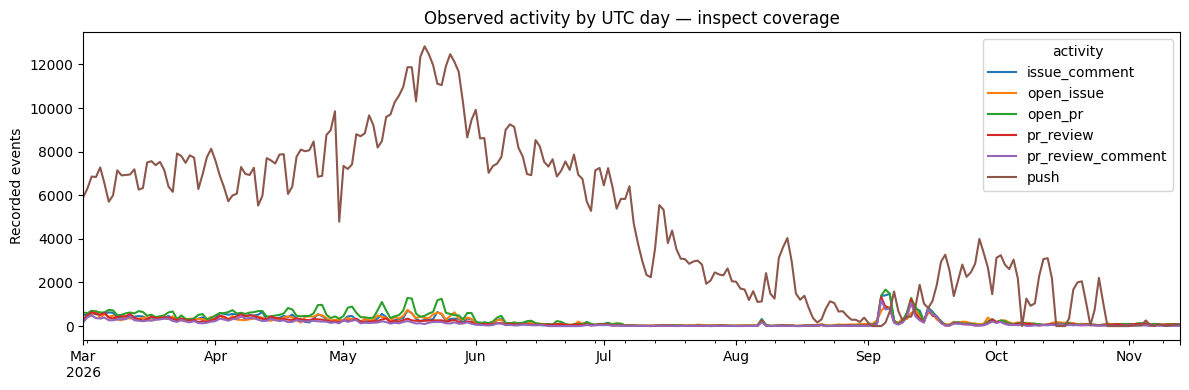

In [7]:
EVENTS, ledger_audit = make_ledger(TABLES)
display(ledger_audit)
ledger_audit.to_csv(OUT / "ledger_audit.csv", index=False)
# Daily variation can reflect both behavior and missing upstream collection; inspect it.
daily_counts = EVENTS.groupby([EVENTS.event_time.dt.floor("D"), "activity"]).size().unstack(fill_value=0)
daily_counts = daily_counts.reindex(pd.date_range(DATA_START, OBSERVATION_END - pd.Timedelta(days=1)), fill_value=0)
daily_counts.to_csv(OUT / "daily_activity_counts.csv")
ax = daily_counts.plot(figsize=(12, 4), title="Observed activity by UTC day — inspect coverage")
ax.set_ylabel("Recorded events"); plt.tight_layout()
plt.savefig(OUT / "daily_activity_counts.png", dpi=160); plt.show()


## 5. Chronological plan with the same historical gap
Daily candidate target starts retain the official forecast's UTC hour. Training candidates
are thinned by `TRAIN_STRIDE_DAYS`; overlapping training labels are correlated, not extra
independent weeks. Validation and holdout are full, nonoverlapping seven-day windows.
More importantly, labels of each earlier split end before the next split's **observation**
cutoff. A random user/row split would not enforce this.

With the default boundaries, the plan is approximately: training Sep 22–Oct 7 starts,
validation Oct 22–29, holdout Nov 6–13 (all at 16:00 UTC). Historical dates need not be
Sundays; the forecast-hour phase and gap are consistent. There are few independent weeks,
so treat conclusions as provisional. Any missing-day exclusions may change this plan.


In [8]:
def candidate_times(observation_end):
    phase = TARGET_START - TARGET_START.normalize()
    candidates = pd.date_range(DATA_START.normalize() + phase, observation_end, freq="D")
    return [t for t in candidates
            if t - GAP >= DATA_START + pd.Timedelta(days=MIN_HISTORY_DAYS)
            and t + HORIZON <= observation_end
            and not interval_has_gap(max(DATA_START, t-GAP-pd.Timedelta(days=GRAPH_LOOKBACK_DAYS)), t-GAP)
            and not interval_has_gap(t, t+HORIZON)]

def select_plan():
    times = candidate_times(OBSERVATION_END)
    if not times: raise ValueError("No fully observed examples after warm-up/gap.")
    holdout = times[-1]
    val = []
    bound = holdout - GAP
    for _ in range(VALIDATION_WEEKS):
        choices = [t for t in times if t + HORIZON <= bound]
        if not choices: raise ValueError("Not enough data for validation; inspect gap and missing dates.")
        val.append(choices[-1]); bound = choices[-1]
    val = sorted(val)
    train = [t for t in times if t + HORIZON <= val[0] - GAP][::TRAIN_STRIDE_DAYS]
    train = train[-MAX_TRAIN_SNAPSHOTS:]
    if not train: raise ValueError("No training dates after the split embargo. Reduce warm-up or add data.")
    assert max(train) + HORIZON <= min(val) - GAP
    assert max(val) + HORIZON <= holdout - GAP
    return train, val, holdout

TRAIN_TIMES, VAL_TIMES, HOLDOUT_TIME = select_plan()
TRAIN_LABEL_AS_OF = min(VAL_TIMES) - GAP
VAL_LABEL_AS_OF = HOLDOUT_TIME - GAP
plan_rows = []
for split, times in [("train", TRAIN_TIMES), ("validation", VAL_TIMES), ("holdout", [HOLDOUT_TIME])]:
    for t in times:
        plan_rows.append({"split": split, "feature_cutoff_exclusive": t-GAP,
                          "target_start": t, "target_end_exclusive": t+HORIZON})
plan = pd.DataFrame(plan_rows)
display(plan)
plan.to_csv(OUT / "chronological_plan.csv", index=False)
print("Train labels known before", TRAIN_LABEL_AS_OF, "; validation labels known before", VAL_LABEL_AS_OF)


,split,feature_cutoff_exclusive,target_start,target_end_exclusive
0,train,2026-03-15,2026-03-22 16:00:00,2026-03-29 16:00:00
1,train,2026-03-18,2026-03-25 16:00:00,2026-04-01 16:00:00
2,train,2026-03-21,2026-03-28 16:00:00,2026-04-04 16:00:00
3,train,2026-03-24,2026-03-31 16:00:00,2026-04-07 16:00:00
4,train,2026-03-27,2026-04-03 16:00:00,2026-04-10 16:00:00
...,...,...,...,...
64,train,2026-09-23,2026-09-30 16:00:00,2026-10-07 16:00:00
65,train,2026-09-26,2026-10-03 16:00:00,2026-10-10 16:00:00
66,train,2026-09-29,2026-10-06 16:00:00,2026-10-13 16:00:00
67,validation,2026-10-15,2026-10-22 16:00:00,2026-10-29 16:00:00


Train labels known before 2026-10-15 00:00:00 ; validation labels known before 2026-10-30 00:00:00


## 6. Build visible tables, close FK references, and create features
No feature or edge uses a row at/after cutoff. The graph begins with recent activity rows,
then recursively adds visible referenced parents so, for example, a recent review can
connect to an older PR. All visible users and repositories are included. A mutable merger
edge is gated separately. Null/unavailable endpoints are omitted, not invented.

Non-temporal features are a constant and log incident degree. Temporal features add:
row age, available-history fraction, and (for users/repositories) cohort activity counts
in 7/14/28 days and per-activity recency. Feature names are saved. No learned scaler sees
validation/holdout data. All graphs use the same temporal visibility/window rules, including
the no-explicit-time ablation; that ablation is not a removal of chronological safeguards.


In [9]:
def visible_frames(t, tables=None):
    tables = TABLES if tables is None else tables
    cutoff = pd.Timestamp(t) - GAP
    if cutoff > OBSERVATION_END: raise ValueError("Snapshot requests unavailable data.")
    start = max(DATA_START, cutoff - pd.Timedelta(days=GRAPH_LOOKBACK_DAYS))
    visible = {name: df.loc[df[ROW_TIME[name]].lt(cutoff)].set_index(PK[name], drop=False).copy()
               for name, df in tables.items()}
    pr = visible["PullRequests"]
    pr.loc[pr.merged_at.isna() | pr.merged_at.ge(cutoff), "merged_by_id"] = pd.NA
    visible_ids = {name: set(df.index) for name, df in visible.items()}
    selected = {name: set(df.index if name in ["Users", "Repositories"]
                          else df.index[df[ROW_TIME[name]].ge(start)]) for name, df in visible.items()}
    while True:
        changed = False
        for source, fks in FKS.items():
            rows = visible[source].loc[sorted(selected[source])]
            for col, dest in fks.items():
                refs = set(rows[col].dropna().astype("int64")) & visible_ids[dest]
                additions = refs - selected[dest]
                if additions: selected[dest].update(additions); changed = True
        if not changed: break
    return cutoff, {n: df.loc[sorted(selected[n])].reset_index(drop=True) for n, df in visible.items()}

def graph_arrays(t, tables=None, ledger=None):
    tables = TABLES if tables is None else tables
    ledger = EVENTS if ledger is None else ledger
    cutoff, frames = visible_frames(t, tables)
    maps = {n: pd.Series(np.arange(len(df)), index=df[PK[n]]) for n, df in frames.items()}
    edges = {}
    degree = {n: np.zeros(len(df), dtype=np.float32) for n, df in frames.items()}
    for source, fks in FKS.items():
        for col, dest in fks.items():
            mapped = frames[source][col].map(maps[dest])
            keep = mapped.notna().to_numpy()
            src = np.flatnonzero(keep).astype(np.int64)
            dst = mapped.loc[keep].to_numpy(dtype=np.int64)
            edges[(source, col, dest)] = (src, dst)
            edges[(dest, "rev_"+source+"_"+col, source)] = (dst, src)
            degree[source] += np.bincount(src, minlength=len(frames[source])).astype(np.float32)
            degree[dest] += np.bincount(dst, minlength=len(frames[dest])).astype(np.float32)
    past = ledger.loc[ledger.known_at.lt(cutoff) & ledger.event_time.lt(cutoff)
                      & ledger.event_time.ge(max(DATA_START, cutoff-pd.Timedelta(days=GRAPH_LOOKBACK_DAYS)))]
    features, names = {}, {}
    coverage = min(1., max(0., (cutoff-DATA_START).total_seconds()/86400/GRAPH_LOOKBACK_DAYS))
    for name, df in frames.items():
        base = np.column_stack([np.ones(len(df)), np.log1p(degree[name])]).astype(np.float32)
        base_names = ["constant", "log_incident_degree"]
        age = ((cutoff - df[ROW_TIME[name]]).dt.total_seconds()/86400).clip(0, GRAPH_LOOKBACK_DAYS).to_numpy()/GRAPH_LOOKBACK_DAYS
        extra = [age, np.full(len(df), coverage)]
        extra_names = ["row_age_scaled", "history_coverage_fraction"]
        if name in ["Users", "Repositories"]:
            key = "user_id" if name == "Users" else "repo_id"
            idx = df[PK[name]]
            for days in COUNT_WINDOWS:
                recent = past.loc[past.event_time.ge(cutoff-pd.Timedelta(days=days))]
                counts = recent.groupby([key, "activity"]).size().unstack("activity")
                counts = counts.reindex(index=idx, columns=ACTIVITIES).fillna(0)
                for activity in ACTIVITIES:
                    extra.append(np.log1p(counts[activity].to_numpy()))
                    extra_names.append(f"log_{activity}_count_{days}d")
            last = past.groupby([key, "activity"]).event_time.max().unstack("activity")
            last = last.reindex(index=idx, columns=ACTIVITIES)
            for activity in ACTIVITIES:
                recency = ((cutoff-pd.to_datetime(last[activity])).dt.total_seconds()/86400)
                extra.append(recency.fillna(GRAPH_LOOKBACK_DAYS).clip(0, GRAPH_LOOKBACK_DAYS).to_numpy()/GRAPH_LOOKBACK_DAYS)
                extra_names.append(f"{activity}_recency_scaled")
        temporal = np.column_stack(extra).astype(np.float32)
        features[name] = {False: base, True: np.column_stack([base, temporal]).astype(np.float32)}
        names[name] = {False: base_names, True: base_names+extra_names}
        assert np.isfinite(features[name][True]).all(), name
    u = frames["Users"]
    mask = u.is_cohort.eq(True).to_numpy()
    return {"t": pd.Timestamp(t), "cutoff": cutoff, "frames": frames,
            "edges": edges, "features": features, "feature_names": names,
            "user_positions": np.flatnonzero(mask), "users": u.loc[mask].reset_index(drop=True)}


## 7. Heterogeneous mean-GraphSAGE in plain PyTorch
For node type v at layer l, the update is a learned root transform plus the mean of
relation-specific transformed neighbor means, followed by ReLU and dropout. Each FK and
reverse FK gets its own neighbor transform. Two layers allow two-hop information flow.
Sparse matrices have shape [destination nodes, source nodes] with 1/degree entries.
Only six logits for cohort users are supervised. The self-only ablation disables all
neighbor terms and keeps the same two root layers and temporal features. Degree features
remain in that control: the Q2 comparison isolates neighbor message passing, not removal
of every relationship-derived summary. It is not parameter-count matched.


In [10]:
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def sparse_mean(src, dst, n_src, n_dst):
    if len(src):
        counts = np.bincount(dst, minlength=n_dst)
        values = (1. / counts[dst]).astype(np.float32)
        indices = torch.from_numpy(np.vstack([dst, src]))
    else:
        values = np.empty(0, np.float32)
        indices = torch.empty((2, 0), dtype=torch.long)
    return torch.sparse_coo_tensor(indices, torch.from_numpy(values), (n_dst, n_src)).coalesce()

@lru_cache(maxsize=CACHE_SNAPSHOTS)
def snapshot(t):
    a = graph_arrays(pd.Timestamp(t))
    a["x"] = {flag: {n: torch.from_numpy(fs[flag]) for n, fs in a["features"].items()} for flag in [False, True]}
    a["adj"] = {r: sparse_mean(src, dst, len(a["frames"][r[0]]), len(a["frames"][r[2]]))
                for r, (src, dst) in a["edges"].items()}
    # Keep compact metadata, not duplicate DataFrames/feature arrays.
    a["node_counts"] = {n: len(df) for n, df in a["frames"].items()}
    for key in ["frames", "features", "edges"]: a.pop(key)
    return a

class MeanSAGELayer(nn.Module):
    def __init__(self, input_dims, hidden, relationships=True):
        super().__init__()
        self.relationships = relationships
        self.root = nn.ModuleDict({n: nn.Linear(d, hidden) for n, d in input_dims.items()})
        self.neighbor = nn.ModuleDict({f"r{i}": nn.Linear(input_dims[r[0]], hidden, bias=False)
                                       for i, r in enumerate(RELATIONS)}) if relationships else nn.ModuleDict()
        self.n_incoming = {n: sum(r[2] == n for r in RELATIONS) for n in input_dims}
    def forward(self, x, adj):
        out = {n: layer(x[n]) for n, layer in self.root.items()}
        if self.relationships:
            for i, r in enumerate(RELATIONS):
                if adj[r]._nnz() == 0: continue
                means = torch.sparse.mm(adj[r], x[r[0]])
                out[r[2]] = out[r[2]] + self.neighbor[f"r{i}"](means) / self.n_incoming[r[2]]
        return out

class HeteroGraphSAGE(nn.Module):
    def __init__(self, dims, temporal=True, relationships=True):
        super().__init__()
        self.temporal = temporal
        self.layer1 = MeanSAGELayer(dims, HIDDEN, relationships)
        self.layer2 = MeanSAGELayer({n: HIDDEN for n in dims}, HIDDEN, relationships)
        self.head = nn.Linear(HIDDEN, len(ACTIVITIES))
    def forward(self, x, adj):
        h = self.layer1(x, adj)
        h = {n: F.dropout(F.relu(v), p=DROPOUT, training=self.training) for n,v in h.items()}
        h = {n: F.relu(v) for n,v in self.layer2(h, adj).items()}
        return self.head(h["Users"])

def model_inputs(a, temporal):
    x = {n: v.to(DEVICE) for n,v in a["x"][temporal].items()}
    adj = {r: v.to(DEVICE) for r,v in a["adj"].items()}
    return x, adj

def new_model(temporal, relationships):
    a = snapshot(TRAIN_TIMES[0])
    dims = {n: v.shape[1] for n,v in a["x"][temporal].items()}
    return HeteroGraphSAGE(dims, temporal, relationships).to(DEVICE)


## 8. Boundary and neural self-checks — run before expensive training
The small example checks cutoff exclusion, delayed openings, PR-vs-issue labels, cohort
negatives, conditional merger edges, independent future labels, and sparse averaging.
It does not estimate model performance.


In [11]:
def tiny_tables(t):
    c = pd.Timestamp(t) - GAP
    old = DATA_START + pd.Timedelta(hours=1)
    future = pd.Timestamp(t) + pd.Timedelta(hours=1)
    rows = {n: [] for n in PK}
    rows["Users"] = [dict(user_id=i, github_user_id=100+i, is_cohort=(i<2), first_seen_at=old) for i in range(3)]
    rows["Repositories"] = [dict(repo_id=0, first_seen_at=old)]
    rows["PullRequests"] = [
        dict(pr_id=0, repo_id=0, author_id=0, first_seen_at=c-pd.Timedelta(days=2), created_at=c-pd.Timedelta(days=2), merged_by_id=2, merged_at=c+pd.Timedelta(hours=1)),
        dict(pr_id=1, repo_id=0, author_id=0, first_seen_at=c, created_at=c),
        dict(pr_id=2, repo_id=0, author_id=0, first_seen_at=future, created_at=future),
        dict(pr_id=3, repo_id=0, author_id=1, first_seen_at=future, created_at=c-pd.Timedelta(days=2)),
    ]
    rows["Issues"] = [
        dict(issue_id=0, repo_id=0, author_id=1, is_pull_request=True, pull_request_id=2, created_at=future, first_seen_at=future),
        dict(issue_id=1, repo_id=0, author_id=0, is_pull_request=False, created_at=future, first_seen_at=future),
        dict(issue_id=2, repo_id=0, author_id=0, is_pull_request=False, created_at=c-pd.Timedelta(days=1), first_seen_at=c-pd.Timedelta(days=1)),
    ]
    rows["IssueComments"] = [dict(comment_id=i, issue_id=(2 if i==0 else 1), repo_id=0, author_id=0,
        created_at=(c-pd.Timedelta(hours=1) if i==0 else future)) for i in range(2)]
    rows["PRReviews"] = [dict(review_id=i, pr_id=(0 if i==0 else 2), repo_id=0, reviewer_id=(1 if i==0 else 0),
        first_seen_at=(c-pd.Timedelta(hours=1) if i==0 else future),
        submitted_at=(c-pd.Timedelta(hours=1) if i==0 else future)) for i in range(2)]
    rows["PRReviewComments"] = [dict(comment_id=i, pr_id=(0 if i==0 else 2), repo_id=0, author_id=(1 if i==0 else 0),
        pull_request_review_id=i, created_at=(c-pd.Timedelta(hours=1) if i==0 else future)) for i in range(2)]
    rows["Pushes"] = [dict(push_id=i, repo_id=0, user_id=0,
        created_at=(c-pd.Timedelta(hours=1) if i==0 else future)) for i in range(2)]
    result = {}
    for name in PK:
        df = pd.DataFrame(rows[name]).reindex(columns=needed_columns(name))
        for col in df:
            if col.endswith("_at"): df[col] = pd.to_datetime(df[col])
        result[name] = df
    return result

def preprocessing_self_checks():
    t = VAL_TIMES[0]
    toy = tiny_tables(t)
    ledger, _ = make_ledger(toy)
    a = graph_arrays(t, toy, ledger)
    y = make_targets(t, a["users"], t+HORIZON, ledger)
    assert np.array_equal(y, np.array([[1]*6, [0]*6], dtype=np.float32))
    assert len(a["frames"]["PullRequests"]) == 1   # excludes row at exact cutoff
    assert len(a["edges"][("PullRequests", "merged_by_id", "Users")][0]) == 0
    for n, df in a["frames"].items(): assert df[ROW_TIME[n]].lt(t-GAP).all()
    later = {n: df.copy() for n,df in toy.items()}
    row = dict(push_id=2, user_id=1, repo_id=0, created_at=t+pd.Timedelta(hours=2))
    later["Pushes"] = pd.concat([later["Pushes"], pd.DataFrame([row])], ignore_index=True)
    later_ledger, _ = make_ledger(later)
    b = graph_arrays(t, later, later_ledger)
    for n in PK: np.testing.assert_array_equal(a["features"][n][True], b["features"][n][True])
    for r in RELATIONS:
        for j in [0,1]: np.testing.assert_array_equal(a["edges"][r][j], b["edges"][r][j])
    assert make_targets(t, b["users"], t+HORIZON, later_ledger)[1, -1] == 1
    print("Synthetic preprocessing/cutoff/label-isolation checks passed.")
    return a, y

def neural_self_checks(a, y):
    seed_everything()
    src, dst = np.array([0,1,1]), np.array([0,0,1])
    adj = sparse_mean(src, dst, 2, 2)
    torch.testing.assert_close(torch.sparse.mm(adj, torch.tensor([[2.],[4.]])), torch.tensor([[3.],[4.]]))
    x = {n: torch.from_numpy(v[True]).to(DEVICE) for n,v in a["features"].items()}
    adjacency = {r: sparse_mean(s,d,len(a["frames"][r[0]]),len(a["frames"][r[2]])).to(DEVICE)
                 for r,(s,d) in a["edges"].items()}
    model = HeteroGraphSAGE({n: v.shape[1] for n,v in x.items()}).to(DEVICE)
    positions = torch.as_tensor(a["user_positions"], dtype=torch.long, device=DEVICE)
    logits = model(x, adjacency)[positions]
    assert tuple(logits.shape) == (len(y), 6)
    loss = F.binary_cross_entropy_with_logits(logits, torch.from_numpy(y).to(DEVICE))
    loss.backward()
    assert torch.isfinite(loss) and torch.isfinite(model.head.weight.grad).all()
    del model, x, adjacency, logits, loss
    print("Sparse-mean and neural forward/backward checks passed.")

_toy, _toy_y = preprocessing_self_checks()
neural_self_checks(_toy, _toy_y)
del _toy, _toy_y
gc.collect()


Synthetic preprocessing/cutoff/label-isolation checks passed.
Sparse-mean and neural forward/backward checks passed.


C:\Users\Bryan\AppData\Local\Temp\ipykernel_17264\275994138.py:13: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:923.)
  return torch.sparse_coo_tensor(indices, torch.from_numpy(values), (n_dst, n_src)).coalesce()


29

## 9. Exact evaluator-compatible metrics and validation-only thresholds
The supplied evaluator defines F1=1 when TP=FP=FN=0. We mirror that convention, including
for rare activities. All six activities are scored by default. If the TAs exclude a missing
activity in the official week, that cannot be guessed from this notebook.

Thresholds are chosen on validation probabilities by coordinate search to maximize
(macro-F1 + micro-F1)/2. Epoch selection uses that validation score. Holdout data never
chooses thresholds, epochs, features, or the final model variant. The grid is intentionally
small given the short validation history. Zero validation positives make a threshold weakly
identified; the per-label support table exposes this limitation.


In [12]:
def metric_arrays(pred, truth):
    p, y = np.asarray(pred).astype(bool), np.asarray(truth).astype(bool)
    assert p.shape == y.shape and p.ndim == 2 and p.shape[1] == 6
    tp = (p & y).sum(0); fp = (p & ~y).sum(0); fn = (~p & y).sum(0)
    denominator = 2*tp + fp + fn
    per = np.divide(2*tp, denominator, out=np.ones(6, dtype=float), where=denominator>0)
    total = denominator.sum()
    micro = float(2*tp.sum()/total) if total else 1.
    return {"macro_f1": float(per.mean()), "micro_f1": micro,
            "score": float((per.mean()+micro)/2), "per_activity_f1": per.tolist(),
            "positive_support": y.sum(0).tolist()}

def choose_thresholds(prob, truth):
    thresholds = np.full(6, 0.5)
    grid = np.array([.05,.10,.15,.20,.25,.30,.35,.40,.45,.50,.60,.70,.80,.90,.95])
    for _ in range(2):
        for j in range(6):
            best = metric_arrays(prob >= thresholds, truth)["score"]
            for value in grid:
                candidate = thresholds.copy(); candidate[j] = value
                score = metric_arrays(prob >= candidate, truth)["score"]
                if score > best + 1e-12: thresholds, best = candidate, score
    return thresholds

def output_frame(users, binary):
    out = pd.DataFrame(np.asarray(binary, dtype=np.int64), columns=ACTIVITIES)
    out.insert(0, "UserID", users.github_user_id.to_numpy(dtype=np.int64))
    assert list(out.columns) == OUTPUT_COLUMNS and out.UserID.is_unique
    assert out[ACTIVITIES].isin([0,1]).all().all()
    return out

assert metric_arrays(np.zeros((2,6)), np.zeros((2,6)))["score"] == 1.


## 10. Training and inference helpers
Only one graph snapshot is moved to the device at a time. We rebuild evicted graphs rather
than saving them to disk. This trades speed for RAM/disk use. Labels are computed only for
eligible cohort users already visible at the snapshot cutoff; no future-user membership
is used to define the training population. Counts, targets, and graph order use explicit
ID mappings, never DataFrame row position from a different preprocessing release.


In [13]:
def targets_for(t, as_of):
    return make_targets(t, eligible_users(t), as_of)

def positive_weights(times, as_of):
    ys = [targets_for(t, as_of) for t in times]
    if any(len(y)==0 for y in ys): raise ValueError("A training date has no visible cohort users.")
    positive = sum(y.sum(0) for y in ys)
    total = sum(len(y) for y in ys)
    weight = np.where(positive>0, (total-positive)/np.maximum(positive,1), 1.).clip(1.,30.)
    prior = positive / total
    return torch.tensor(weight, dtype=torch.float32, device=DEVICE), prior.astype(np.float32)

def train_epoch(model, optimizer, criterion, times, label_as_of):
    model.train(); losses = []
    for t in times:
        a = snapshot(t)
        x, adj = model_inputs(a, model.temporal)
        positions = torch.as_tensor(a["user_positions"], dtype=torch.long, device=DEVICE)
        y = torch.from_numpy(make_targets(t, a["users"], label_as_of)).to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x, adj)[positions]
        loss = criterion(logits, y)
        if not torch.isfinite(loss): raise FloatingPointError("Non-finite training loss.")
        loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(), 5.)
        optimizer.step(); losses.append(float(loss.detach().cpu()))
        del x, adj, logits, loss, y, positions
    return float(np.mean(losses))

@torch.no_grad()
def infer(model, times, label_as_of=None):
    model.eval(); probabilities, truths, identities = [], [], []
    for t in times:
        a = snapshot(t); x, adj = model_inputs(a, model.temporal)
        positions = torch.as_tensor(a["user_positions"], dtype=torch.long, device=DEVICE)
        prob = torch.sigmoid(model(x, adj)[positions]).cpu().numpy()
        probabilities.append(prob)
        identities.append(a["users"][["user_id", "github_user_id"]].assign(target_start=t))
        if label_as_of is not None: truths.append(make_targets(t, a["users"], label_as_of))
        del x, adj, positions
    return np.concatenate(probabilities), (np.concatenate(truths) if truths else None), pd.concat(identities, ignore_index=True)

def fit_variant(name, temporal, relationships):
    seed_everything()
    model = new_model(temporal, relationships)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    weights, _ = positive_weights(TRAIN_TIMES, TRAIN_LABEL_AS_OF)
    criterion = nn.BCEWithLogitsLoss(pos_weight=weights)
    best_score, best_state, best_epoch, best_thresholds, stale = -1., None, 0, None, 0
    history = []
    for epoch in range(1, EPOCHS+1):
        loss = train_epoch(model, optimizer, criterion, TRAIN_TIMES, TRAIN_LABEL_AS_OF)
        prob, truth, _ = infer(model, VAL_TIMES, VAL_LABEL_AS_OF)
        thresholds = choose_thresholds(prob, truth)
        score = metric_arrays(prob >= thresholds, truth)["score"]
        history.append({"epoch": epoch, "train_loss": loss, "validation_score": score})
        print(f"{name} | epoch {epoch:02d} | loss {loss:.4f} | validation score {score:.4f}")
        if score > best_score + 1e-8:
            best_score, best_epoch = score, epoch
            best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}
            best_thresholds = thresholds.copy(); stale = 0
        else:
            stale += 1
            if stale >= PATIENCE: break
    model.load_state_dict(best_state)
    pd.DataFrame(history).to_csv(OUT / f"training_{name}.csv", index=False)
    torch.save({"state_dict": best_state, "thresholds": best_thresholds.tolist(), "best_epoch": best_epoch,
                "variant": name, "temporal": temporal, "relationships": relationships}, OUT / f"historical_{name}.pt")
    result = {"name": name, "temporal": temporal, "relationships": relationships,
              "state": best_state, "thresholds": best_thresholds, "best_epoch": best_epoch,
              "history": history}
    return model, result


## 11. Run experiments — the expensive section
`RUN_ABLATIONS=True` trains three variants. Q2 compares self-only+time with GraphSAGE+time;
Q3 compares GraphSAGE without/with explicit time features. This is a small ablation study,
not proof of causality or guaranteed improvement. The same split, labels, graph visibility,
hidden size, optimizer, and epoch budget are used. Parameter counts are recorded because
adding relational transforms also adds parameters.

The reference copies the last **available** seven days before the observation cutoff,
not a week of information hidden by the gap. Final submission always uses `sage_time`;
it is not selected by the holdout scores. You may later select alternatives using only
validation and rerun the complete experiment record.


In [14]:
VARIANTS = {"sage_time": (True, True)}
if RUN_ABLATIONS:
    VARIANTS = {"self_only_time": (True, False), "sage_no_time": (False, True), **VARIANTS}
RESULTS, comparison_rows = {}, []
for name, (temporal, relationships) in VARIANTS.items():
    print("\nStarting", name)
    model, result = fit_variant(name, temporal, relationships)
    val_prob, val_y, val_users = infer(model, VAL_TIMES, VAL_LABEL_AS_OF)
    hold_prob, hold_y, hold_users = infer(model, [HOLDOUT_TIME], OBSERVATION_END)
    result["validation"] = metric_arrays(val_prob >= result["thresholds"], val_y)
    result["holdout"] = metric_arrays(hold_prob >= result["thresholds"], hold_y)
    result["parameter_count"] = sum(p.numel() for p in model.parameters())
    RESULTS[name] = result
    for split in ["validation", "holdout"]:
        comparison_rows.append({"method": name, "split": split, "parameters": result["parameter_count"],
            **{k: result[split][k] for k in ["macro_f1", "micro_f1", "score"]}})
    # The holdout has one target week, so each user appears exactly once.
    output_frame(hold_users, hold_prob >= result["thresholds"]).to_csv(OUT / f"holdout_{name}.csv", index=False)
    output_frame(hold_users, hold_y).to_csv(OUT / "holdout_truth.csv", index=False)
    val_export = val_users.copy()
    for j,a in enumerate(ACTIVITIES):
        val_export[f"prob_{a}"] = val_prob[:,j]; val_export[f"truth_{a}"] = val_y[:,j].astype(int)
    val_export.to_csv(OUT / f"validation_probabilities_{name}.csv", index=False)
    del model; gc.collect()
    if DEVICE.type == "cuda": torch.cuda.empty_cache()

# Past-available-week reference, evaluated on the same holdout population.
hold_users = snapshot(HOLDOUT_TIME)["users"]
cutoff = HOLDOUT_TIME - GAP
past = EVENTS.loc[EVENTS.known_at.lt(cutoff) & EVENTS.event_time.lt(cutoff)
                  & EVENTS.event_time.ge(cutoff-pd.Timedelta(days=7))]
counts = past.groupby(["user_id", "activity"]).size().unstack("activity")
reference_pred = counts.reindex(index=hold_users.user_id, columns=ACTIVITIES).fillna(0).gt(0).to_numpy()
reference_truth = make_targets(HOLDOUT_TIME, hold_users, OBSERVATION_END)
reference_metrics = metric_arrays(reference_pred, reference_truth)
comparison_rows.append({"method": "copy_last_available_week", "split": "holdout", "parameters": 0,
    **{k: reference_metrics[k] for k in ["macro_f1", "micro_f1", "score"]}})
output_frame(hold_users, reference_pred).to_csv(OUT / "holdout_reference.csv", index=False)
comparison = pd.DataFrame(comparison_rows)
display(comparison)
comparison.to_csv(OUT / "experiment_comparison.csv", index=False)



Starting self_only_time
self_only_time | epoch 01 | loss 1.2043 | validation score 0.3741
self_only_time | epoch 02 | loss 1.0525 | validation score 0.3857
self_only_time | epoch 03 | loss 1.0162 | validation score 0.3945
self_only_time | epoch 04 | loss 1.0006 | validation score 0.3872
self_only_time | epoch 05 | loss 1.0093 | validation score 0.3720
self_only_time | epoch 06 | loss 1.0078 | validation score 0.3694
self_only_time | epoch 07 | loss 1.0028 | validation score 0.3813

Starting sage_no_time
sage_no_time | epoch 01 | loss 1.1343 | validation score 0.3486
sage_no_time | epoch 02 | loss 1.0358 | validation score 0.3534
sage_no_time | epoch 03 | loss 1.0196 | validation score 0.3432
sage_no_time | epoch 04 | loss 1.0096 | validation score 0.3261
sage_no_time | epoch 05 | loss 1.0354 | validation score 0.3358
sage_no_time | epoch 06 | loss 1.0271 | validation score 0.3325

Starting sage_time
sage_time | epoch 01 | loss 1.1529 | validation score 0.3738
sage_time | epoch 02 | lo

,method,split,parameters,macro_f1,micro_f1,score
0,self_only_time,validation,11462,0.367566,0.421416,0.394491
1,self_only_time,holdout,11462,0.320842,0.256112,0.288477
2,sage_no_time,validation,52934,0.323925,0.382870,0.353397
3,sage_no_time,holdout,52934,0.275366,0.225225,0.250296
4,sage_time,validation,68294,0.354686,0.403894,0.379290
5,sage_time,holdout,68294,0.317270,0.247239,0.282255
6,copy_last_available_week,holdout,0,0.279647,0.245232,0.262440


## 12. Results for Q2/Q3 and the official evaluator
These figures are created from measured results when you run the notebook. No scores
are pre-filled. Include only results actually obtained in your slides and video.


,activity,validation_positives,holdout_positives,threshold,holdout_f1
0,open_pr,313,362,0.60,0.261993
1,open_issue,174,187,0.70,0.411765
2,issue_comment,209,212,0.60,0.360731
3,pr_review,203,228,0.70,0.365591
4,pr_review_comment,98,66,0.80,0.368421
5,push,1095,165,0.45,0.135119


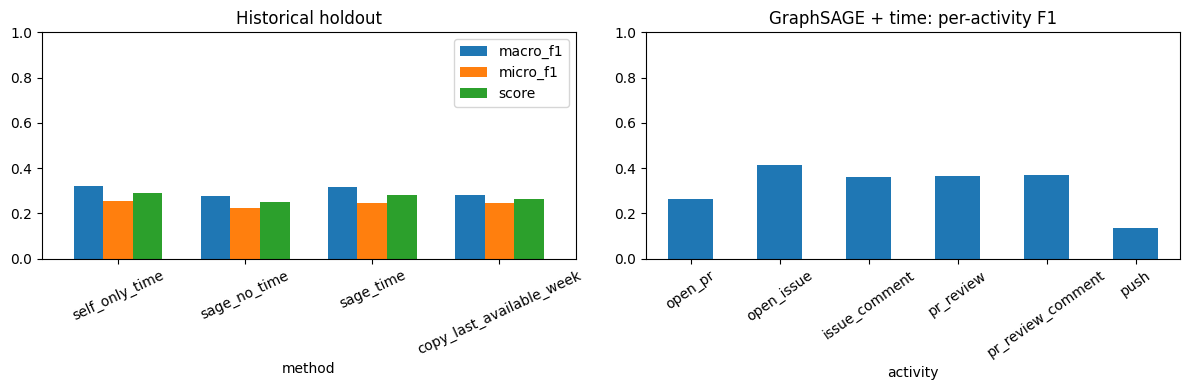

In [15]:
main_result = RESULTS["sage_time"]
per_activity = pd.DataFrame({
    "activity": ACTIVITIES,
    "validation_positives": main_result["validation"]["positive_support"],
    "holdout_positives": main_result["holdout"]["positive_support"],
    "threshold": main_result["thresholds"],
    "holdout_f1": main_result["holdout"]["per_activity_f1"],
})
display(per_activity)
per_activity.to_csv(OUT / "per_activity_results.csv", index=False)
fig, axes = plt.subplots(1,2, figsize=(12,4))
hold = comparison.loc[comparison.split.eq("holdout")].set_index("method")
hold[["macro_f1","micro_f1","score"]].plot.bar(ax=axes[0], width=.7, ylim=(0,1), rot=25, title="Historical holdout")
per_activity.plot.bar(x="activity", y="holdout_f1", ax=axes[1], legend=False, rot=35, ylim=(0,1), title="GraphSAGE + time: per-activity F1")
plt.tight_layout(); plt.savefig(OUT / "holdout_comparisons.png", dpi=180); plt.show()

if EVALUATOR.is_file():
    subprocess.run([sys.executable, str(EVALUATOR), "--pred", str(OUT/"holdout_sage_time.csv"),
                    "--truth", str(OUT/"holdout_truth.csv")], check=True)
else:
    print("Official scripts/evaluate.py not found. Local matching metrics ran; restore the supplied evaluator before submission.")


## 13. Final refit and exact submission CSV
Set your student ID and `RUN_FINAL=True` in Section 2 after the historical run works.
The official test list is needed only here; do not substitute `cohort.txt` for it.
Only eligible historical labels known before the final observation cutoff are used.
Refitting may include old validation/holdout history: the previously reported holdout
belongs to the separately fitted historical model and remains unchanged.

The selected epoch count and validation thresholds are reused. The model is retrained
from a fixed seed; threshold transfer to a refit model is an approximation, so report it.
If a test user has no visible cohort node in this short collection period, its prediction
uses the six positive rates from final training history. This cold-start fallback is
explicitly logged; no future user activity is consulted. The output preserves test order
and maps stable `github_user_id` codes, not internal `user_id` row numbers.


In [29]:
final_record = {"ran": False}
if RUN_FINAL:
    if not STUDENT_ID.isdigit(): raise ValueError("Set STUDENT_ID to your numeric student ID.")
    if not TEST_INPUT.is_file(): raise FileNotFoundError("Download the latest official submission/test_input.csv.")
    if not EVALUATOR.is_file(): raise FileNotFoundError("Restore the supplied scripts/evaluate.py before final export.")
    test_users = pd.read_csv(TEST_INPUT, dtype={"UserID": "int64"})
    if list(test_users.columns) != ["UserID"] or test_users.empty or test_users.UserID.isna().any() or test_users.UserID.duplicated().any():
        raise ValueError("Official test list must have one UserID column and unique, nonmissing users.")
    final_cutoff = TARGET_START - GAP
    final_times = candidate_times(final_cutoff)[::TRAIN_STRIDE_DAYS][-MAX_TRAIN_SNAPSHOTS:]
    if not final_times: raise ValueError("No fully observed final-refit training examples.")
    snapshot.cache_clear(); gc.collect()
    seed_everything()
    final_model = new_model(temporal=True, relationships=True)
    optimizer = torch.optim.Adam(final_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    weights, prior = positive_weights(final_times, final_cutoff)
    criterion = nn.BCEWithLogitsLoss(pos_weight=weights)
    for epoch in range(1, main_result["best_epoch"]+1):
        loss = train_epoch(final_model, optimizer, criterion, final_times, final_cutoff)
        print(f"Final refit epoch {epoch:02d} | loss {loss:.4f}")
    prob, _, ids = infer(final_model, [TARGET_START])  # no call to make_targets for official week
    available = pd.DataFrame(prob, columns=ACTIVITIES)
    available.insert(0, "UserID", ids.github_user_id.to_numpy(dtype=np.int64))
    merged = test_users.merge(available, on="UserID", how="left", validate="one_to_one", sort=False)
    cold_start = merged[ACTIVITIES].isna().all(axis=1)
    for j,a in enumerate(ACTIVITIES): merged[a] = merged[a].fillna(float(prior[j]))
    assert np.isfinite(merged[ACTIVITIES].to_numpy()).all()
    binary = merged[ACTIVITIES].to_numpy() >= main_result["thresholds"]
    submission = pd.DataFrame(binary.astype(np.int64), columns=ACTIVITIES)
    submission.insert(0, "UserID", test_users.UserID.to_numpy(dtype=np.int64))
    assert submission.UserID.tolist() == test_users.UserID.tolist()
    output_path = OUT / f"output_{STUDENT_ID}.csv"
    submission.to_csv(output_path, index=False)
    subprocess.run([sys.executable, str(EVALUATOR), "--pred", str(output_path), "--input", str(TEST_INPUT)], check=True)
    pd.DataFrame({"UserID": test_users.UserID, "cold_start_prior_used": cold_start}).to_csv(OUT/"final_user_coverage.csv", index=False)
    final_record = {"ran": True, "output": str(output_path), "cold_start_users": int(cold_start.sum()),
                    "test_users": len(test_users), "prior": prior.tolist(), "feature_cutoff": str(final_cutoff),
                    "train_times": list(map(str,final_times)), "epochs": main_result["best_epoch"]}
    torch.save({"state_dict": {k:v.detach().cpu() for k,v in final_model.state_dict().items()},
                "thresholds": main_result["thresholds"].tolist(), "prior": prior.tolist(),
                "activities": ACTIVITIES, "record": final_record,
                "feature_names": snapshot(TARGET_START)["feature_names"]}, OUT/"final_graphsage.pt")
    display(submission.head())
    print("Saved:", output_path.resolve(), "| cold-start prior users:", int(cold_start.sum()))
else:
    print("Final refit/export skipped. Set STUDENT_ID and RUN_FINAL=True when ready.")


Final refit epoch 01 | loss 1.1494
Final refit epoch 02 | loss 1.0103
Final refit epoch 03 | loss 0.9978
Final refit epoch 04 | loss 0.9961
Final refit epoch 05 | loss 0.9861


,UserID,open_pr,open_issue,issue_comment,pr_review,pr_review_comment,push
0,100431196554039,1,1,1,0,0,1
1,100457905686263,0,0,0,0,0,0
2,101051236896852,0,0,0,0,0,0
3,101306412508088,0,0,0,0,0,0
4,101380187937965,0,1,1,0,0,1


Saved: C:\Users\Bryan\Downloads\Big Data Analytics Techniques and Applications\BigData2026-Assignment2\generated_graphsage\output_115701801.csv | cold-start prior users: 0
